# 01 · Data: tiles, solar farms, and the NASA POWER climate universe

This notebook builds the data for the ask-the-map check (embedding design, amendment A1 in `PLAN.md`). Nothing
here answers or scores a question.

**Fixed in advance (`PLAN.md`, `configs/feasibility.yaml`).**
- **Tiles:** 20 km squares, 30 m pixels, land year 2024 (AlphaEarth and CDL). North Dakota: Earth Engine plus
  the National Wetlands Inventory (state file downloaded here). Every other tile from Earth Engine, with USPVDB
  solar farms.
- **Areas:** North Dakota and North Carolina (training and test tiles); South Dakota, Nebraska, Kansas, Virginia,
  South Carolina (extra training tiles); Minnesota and Georgia (held-out states, test tiles only).
- **Climate universe:** NASA POWER daily data 2001–2025 for every land cell in the Plains and South-east boxes.
  Cells in Minnesota and Georgia are flagged as held out.
- **Check D:** ≤ 1% of pixels missing an embedding in every tile; POWER complete in every universe cell; every
  tile pixel falls in a universe land cell; ≥ 15 farms in the North Carolina test tiles.

In [1]:
import json
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from askmap.config import PROJECT_ROOT, data_root, load_config, load_env
from askmap.data import fetch_file, read_uspvdb
from askmap.earth_engine import init_earth_engine
from askmap.manifest import Manifest
from askmap.power import add_derived, fetch_daily, pixel_cells
from askmap.tiles import (
    area_tiles,
    build_ee_tile,
    build_nwi_tile,
    check_tile,
    pixel_lonlat,
    save_tile,
    solar_farm_ids,
)
from askmap.universe import Universe, assign_states, box_of, land_cells

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
load_env()
T_START = time.time()
YEAR = cfg["land_year"]
TILE_DIR = ROOT / "tiles"
TILE_DIR.mkdir(parents=True, exist_ok=True)
tile_manifest = Manifest(TILE_DIR)
P = cfg["power"]

## Solar farms (USPVDB) and state outlines

In [2]:
u = cfg["uspvdb"]
zip_path = fetch_file(u["url"], ROOT / "raw" / "uspvdbGeoJSON.zip", Manifest(ROOT / "raw"))
pv = read_uspvdb(zip_path, u["member"])
print(
    f"USPVDB: {len(pv):,} facilities; install years {int(pv.p_year.min())}-{int(pv.p_year.max())}; "
    f"{int(pv.p_year.isna().sum())} without a year"
)
states_zip = fetch_file(P["states_url"], ROOT / "raw" / "cb_2023_us_state_20m.zip", Manifest(ROOT / "raw"))
states = gpd.read_file(f"zip://{states_zip}")
print(f"State outlines: {len(states)}")

USPVDB: 6,611 facilities; install years 1985-2025; 0 without a year
State outlines: 52


## Tiles

In [3]:
info = []
ee_ready = False
for area, acfg in cfg["areas"].items():
    for name, (tile, role) in area_tiles(acfg, cfg["grid"]).items():
        path = TILE_DIR / f"{area}_{name}.npz"
        t0 = time.time()
        if not tile_manifest.is_current(path):
            if not ee_ready:
                _ = init_earth_engine()  # the project ID is read from .env and not printed
                ee_ready = True
            if acfg["source"] == "earth_engine_nwi":
                # the state's NWI geodatabase is downloaded once, only when a tile needs building
                nwi_zip = fetch_file(
                    acfg["nwi_url"], ROOT / acfg["nwi_zip"], Manifest(ROOT / "raw"), timeout=3600
                )
                arrays = build_nwi_tile(tile, YEAR, f"zip://{nwi_zip}!{acfg['nwi_gdb']}", acfg["nwi_layer"])
                src = "Earth Engine + NWI"
            elif acfg["source"] == "earth_engine":
                arrays = build_ee_tile(tile, YEAR, pv, u["last_year"])
                src = "Earth Engine + USPVDB"
            else:
                raise ValueError(f"unknown tile source {acfg['source']!r}")
            save_tile(
                path,
                arrays,
                tile_manifest,
                area=area,
                tile=name,
                year=YEAR,
                source=src,
                x0=tile.x0,
                y1=tile.y1,
                size_px=tile.size_px,
                res_m=tile.res_m,
            )
            built = round(time.time() - t0, 1)
        else:
            built = None
        z = np.load(path)
        arrays = {k: z[k] for k in z.files}
        row = {
            "area": area,
            "area_role": acfg["role"],
            "tile": name,
            "role": role,
            "build_seconds": built,
            "MB": round(path.stat().st_size / 1e6, 1),
            **check_tile(arrays, max_missing=0.01),
        }
        if "solar" in arrays:
            row["farms_built_by_2023"] = len(solar_farm_ids(pv, tile, u["last_year"]))
            row["solar_pixels"] = int((arrays["solar"] == 1).sum())
        if "nwi" in arrays:
            row["nwi_wetland_share"] = round(float((arrays["nwi"] == 1).mean()), 3)
        info.append(row)
        print(row)
tiles_df = pd.DataFrame(info)

{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Stutsman', 'role': 'train', 'build_seconds': None, 'MB': 24.0, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.067}
{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Barnes', 'role': 'train', 'build_seconds': None, 'MB': 23.6, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.044}


{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Wells', 'role': 'train', 'build_seconds': None, 'MB': 23.5, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.026}
{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Kidder', 'role': 'test', 'build_seconds': None, 'MB': 22.4, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.072}


{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Foster', 'role': 'test', 'build_seconds': None, 'MB': 23.5, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.04}
{'area': 'north_dakota', 'area_role': 'seen', 'tile': 'Eddy', 'role': 'test', 'build_seconds': None, 'MB': 23.8, 'missing_embedding_share': 0.0, 'nwi_wetland_share': 0.118}


{'area': 'north_carolina', 'area_role': 'seen', 'tile': 'NC1', 'role': 'train', 'build_seconds': None, 'MB': 26.5, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 15, 'solar_pixels': 1703}


{'area': 'north_carolina', 'area_role': 'seen', 'tile': 'NC2', 'role': 'train', 'build_seconds': None, 'MB': 26.3, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 11, 'solar_pixels': 670}


...

{'area': 'south_carolina', 'area_role': 'extra', 'tile': 'SC1', 'role': 'train', 'build_seconds': None, 'MB': 26.3, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 4, 'solar_pixels': 312}
{'area': 'south_carolina', 'area_role': 'extra', 'tile': 'SC2', 'role': 'train', 'build_seconds': None, 'MB': 25.8, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 4, 'solar_pixels': 1162}


{'area': 'minnesota', 'area_role': 'heldout', 'tile': 'MN1', 'role': 'test', 'build_seconds': None, 'MB': 25.4, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 25, 'solar_pixels': 4352}


{'area': 'minnesota', 'area_role': 'heldout', 'tile': 'MN2', 'role': 'test', 'build_seconds': None, 'MB': 26.3, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 20, 'solar_pixels': 1116}
{'area': 'minnesota', 'area_role': 'heldout', 'tile': 'MN3', 'role': 'test', 'build_seconds': None, 'MB': 25.1, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 17, 'solar_pixels': 595}


{'area': 'georgia', 'area_role': 'heldout', 'tile': 'GA1', 'role': 'test', 'build_seconds': None, 'MB': 25.9, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 5, 'solar_pixels': 854}
{'area': 'georgia', 'area_role': 'heldout', 'tile': 'GA2', 'role': 'test', 'build_seconds': None, 'MB': 25.2, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 4, 'solar_pixels': 7222}


{'area': 'georgia', 'area_role': 'heldout', 'tile': 'GA3', 'role': 'test', 'build_seconds': None, 'MB': 26.1, 'missing_embedding_share': 0.0, 'farms_built_by_2023': 4, 'solar_pixels': 275}


## The NASA POWER climate universe (daily, 2001–2025)

In [4]:
daily, parts = {}, []
for box, b in P["boxes"].items():
    t0 = time.time()
    raw = fetch_daily(P, b, ROOT / "power" / f"universe_{box}_daily.nc")
    daily[box] = add_derived(raw, P["low_wind_sun_pct"])
    parts.append(land_cells(daily[box], box))
    print(f"{box}: grid {dict(daily[box].sizes)}, land cells {len(parts[-1])}, {time.time() - t0:.0f}s")
cells = assign_states(pd.concat(parts, ignore_index=True), states, P["heldout_states"])
uni = Universe(cells=cells, daily=daily)
cells.to_parquet(ROOT / "power" / "universe_cells.parquet")
print(
    f"Universe: {len(cells)} land cells, {int(cells.heldout.sum())} in held-out states "
    f"({cells[cells.heldout].state.value_counts().to_dict()})"
)

plains: grid {'time': 9131, 'lat': 28, 'lon': 21}, land cells 588, 5s


southeast: grid {'time': 9131, 'lat': 20, 'lon': 16}, land cells 261, 0s
Universe: 849 land cells, 124 in held-out states ({'MN': 78, 'GA': 46})


## Every tile pixel must fall in a universe land cell

In [5]:
tile_cells = {}
for area, acfg in cfg["areas"].items():
    for name, (tile, _role) in area_tiles(acfg, cfg["grid"]).items():
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        ds = daily[box]
        iy, ix = pixel_cells(ds.lat.values, ds.lon.values, lat, lon)
        rows = uni.index(box, iy, ix)
        tile_cells[f"{area}_{name}"] = sorted(set(rows.ravel().tolist()))
        bad = acfg["role"] != "heldout" and cells.loc[tile_cells[f"{area}_{name}"], "heldout"].any()
        assert not bad, f"{area} {name} falls in a held-out state cell"
used = sorted({c for v in tile_cells.values() for c in v})
missing = 0
for box, ds in daily.items():
    g = cells[cells.box == box]
    for v in ds.data_vars:
        missing += int((~np.isfinite(ds[v].values[:, g.iy.to_numpy(), g.ix.to_numpy()])).sum())
print(f"POWER cells touched by tiles: {len(used)}; missing daily values in universe cells: {missing}")
(ROOT / "power" / "tile_cells.json").write_text(json.dumps(tile_cells))

POWER cells touched by tiles: 47; missing daily values in universe cells: 0


868

## Check D

In [6]:
nc_test_farms = int(tiles_df.query("area == 'north_carolina' and role == 'test'").farms_built_by_2023.sum())
d_tiles = bool((tiles_df.missing_embedding_share <= 0.01).all())
d_power = missing == 0
d_farms = nc_test_farms >= 15
verdict = {
    "D_tiles": d_tiles,
    "D_power": d_power,
    "D_farms": d_farms,
    "D": d_tiles and d_power and d_farms,
    "nc_test_farms": nc_test_farms,
    "n_tiles": len(tiles_df),
    "universe_cells": len(cells),
    "heldout_cells": int(cells.heldout.sum()),
    "tile_cells": len(used),
    "tiles": tiles_df.to_dict("records"),
    "minutes": round((time.time() - T_START) / 60, 1),
    "data_MB": {
        "tiles": round(sum(p.stat().st_size for p in TILE_DIR.glob("*.npz")) / 1e6),
        "power": round(sum(p.stat().st_size for p in (ROOT / "power").glob("*.nc")) / 1e6),
    },
}
(RES / "01_data.json").write_text(json.dumps(verdict, indent=1, default=str))
print(
    f"D (data): {'PASS' if verdict['D'] else 'FAIL'}  tiles {d_tiles}, POWER {d_power}, "
    f"farms in NC test tiles {nc_test_farms} (need >= 15)"
)
print(f"Run time {verdict['minutes']} min; data {verdict['data_MB']} MB")
tiles_df

D (data): PASS  tiles True, POWER True, farms in NC test tiles 32 (need >= 15)
Run time 0.2 min; data {'tiles': 724, 'power': 266} MB


,area,area_role,tile,role,build_seconds,MB,missing_embedding_share,nwi_wetland_share,farms_built_by_2023,solar_pixels
0,north_dakota,seen,Stutsman,train,None,24.0,0.0,0.067,NaN,NaN
1,north_dakota,seen,Barnes,train,None,23.6,0.0,0.044,NaN,NaN
2,north_dakota,seen,Wells,train,None,23.5,0.0,0.026,NaN,NaN
3,north_dakota,seen,Kidder,test,None,22.4,0.0,0.072,NaN,NaN
4,north_dakota,seen,Foster,test,None,23.5,0.0,0.040,NaN,NaN
5,north_dakota,seen,Eddy,test,None,23.8,0.0,0.118,NaN,NaN
6,north_carolina,seen,NC1,train,None,26.5,0.0,NaN,15.0,1703.0
7,north_carolina,seen,NC2,train,None,26.3,0.0,NaN,11.0,670.0
8,north_carolina,seen,NC3,train,None,26.5,0.0,NaN,11.0,6252.0
9,north_carolina,seen,NC4,test,None,26.9,0.0,NaN,11.0,995.0


## Where the tiles and the climate universe are

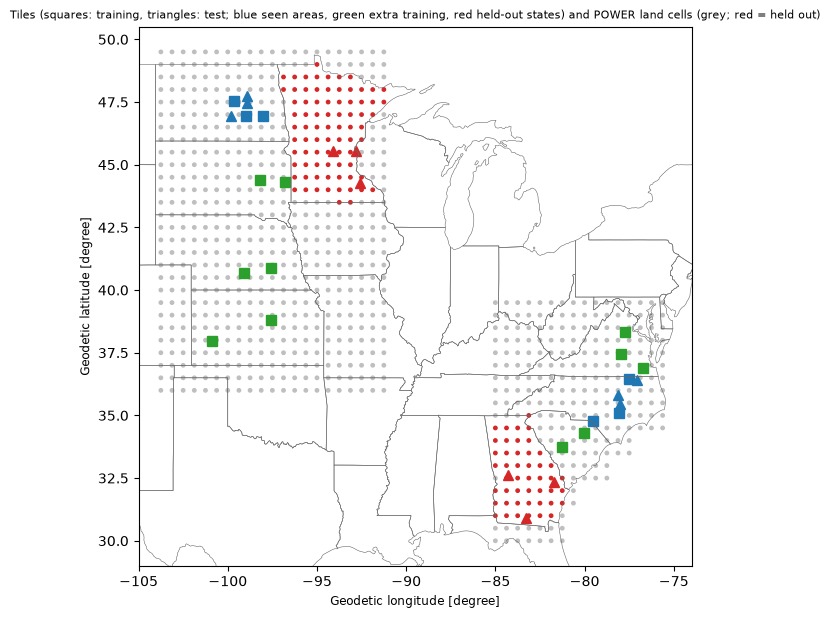

In [7]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(cells.lon, cells.lat, s=6, c=np.where(cells.heldout, "C3", "0.75"), label="POWER land cells")
for acfg in cfg["areas"].values():
    for tile, role in area_tiles(acfg, cfg["grid"]).values():
        lon, lat = pixel_lonlat(tile)
        colour = {"seen": "C0", "extra": "C2", "heldout": "C3"}[acfg["role"]]
        ax.plot(lon.mean(), lat.mean(), "s" if role == "train" else "^", color=colour, ms=7)
states.boundary.plot(ax=ax, lw=0.4, color="0.4")
ax.set_xlim(-105, -74)
ax.set_ylim(29, 50.5)
ax.set_title(
    "Tiles (squares: training, triangles: test; blue seen areas, green extra training, red held-out "
    "states) and POWER land cells (grey; red = held out)",
    fontsize=8,
)
fig.savefig(FIG / "01_map.png", dpi=110)
plt.show()